<a href="https://colab.research.google.com/github/DinaKSari/244107020072_PEMBELAJARAN_MESIN/blob/main/PBL_TG11_244107020072_DINA_KUMALA_SARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRAKTIKUM 1

In [1]:
!pip install ipywidgets

In [2]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import pandas as pd

In [3]:
df = pd.read_csv('/content/.config/lettuce.csv', encoding='latin1')
df.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


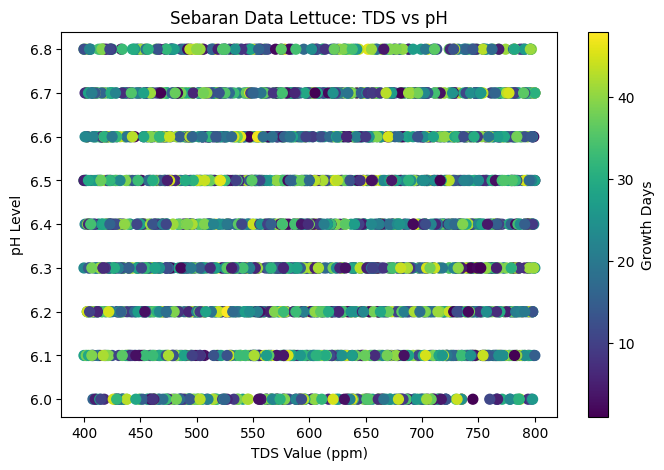

In [4]:
# Visualisasi awal sebaran data Lettuce (misal Hubungan TDS Value vs pH Level)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df['TDS Value (ppm)'], df['pH Level'], c=df['Growth Days'], cmap='viridis', s=50)
plt.xlabel('TDS Value (ppm)')
plt.ylabel('pH Level')
plt.title('Sebaran Data Lettuce: TDS vs pH')
plt.colorbar(label='Growth Days')
plt.show()

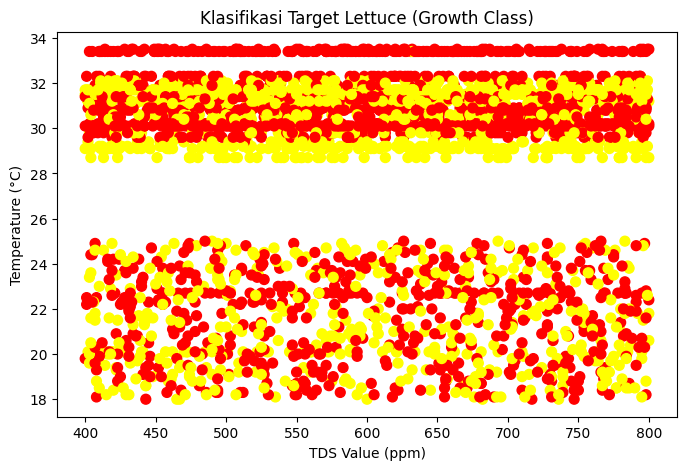

In [5]:
# Menyiapkan fitur klasifikasi sederhana (misal mengelompokkan pertumbuhan hari > 25 sebagai kelas 1, sisanya 0)
df['Growth_Class'] = (df['Growth Days'] > 25).astype(int)

X = df[['TDS Value (ppm)', 'Temperature (°C)']].values
y = df['Growth_Class'].values

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('TDS Value (ppm)')
plt.ylabel('Temperature (°C)')
plt.title('Klasifikasi Target Lettuce (Growth Class)')
plt.show()

In [6]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1.0)
model.fit(X, y)

SVC(kernel='linear')

In [7]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

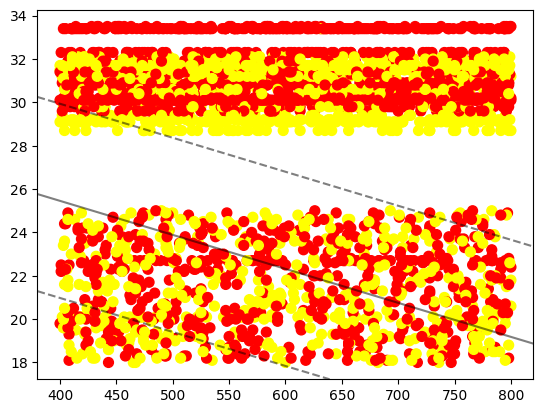

In [8]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [9]:
model.support_vectors_

array([[582. ,  33.4],
       [678. ,  33.4],
       [420. ,  33.4],
       ...,
       [668. ,  22.5],
       [476. ,  22.5],
       [521. ,  22.6]], shape=(2125, 2))

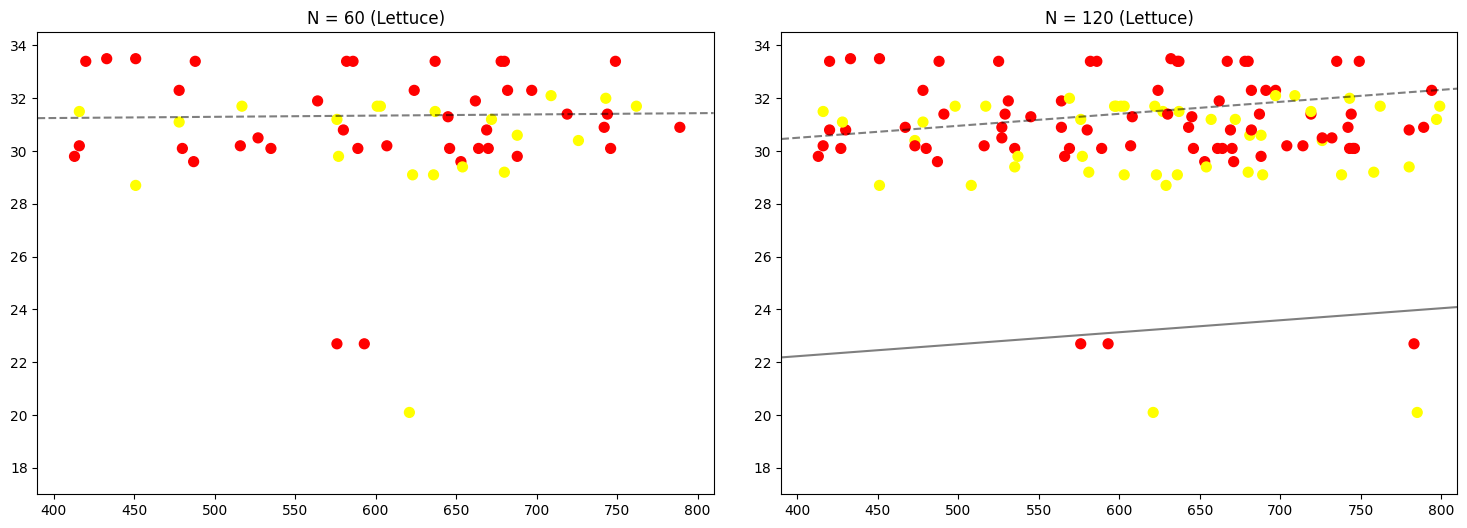

In [10]:
def plot_svm_lettuce(N=10, ax=None):
    # Mengambil sampel data lettuce agar visualisasi bervariasi berdasarkan N
    X_sub = X[:N]
    y_sub = y[:N]

    # Latih model SVM linier pada sub-sampel lettuce
    model_sub = SVC(kernel='linear', C=1.0)
    model_sub.fit(X_sub, y_sub)

    ax = ax or plt.gca()
    ax.scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, s=50, cmap='autumn')
    ax.set_xlim(df['TDS Value (ppm)'].min() - 10, df['TDS Value (ppm)'].max() + 10)
    ax.set_ylim(df['Temperature (°C)'].min() - 1, df['Temperature (°C)'].max() + 1)
    plot_svc_decision_function(model_sub, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm_lettuce(N, axi)
    axi.set_title('N = {0} (Lettuce)'.format(N))

In [12]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, menggunakan fungsi plot_svm_lettuce yang sesuai

from ipywidgets import interact, fixed
interact(plot_svm_lettuce, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm_lettuce(N=10, ax=None)>

# PRAKTIKUM 2

In [13]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [14]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

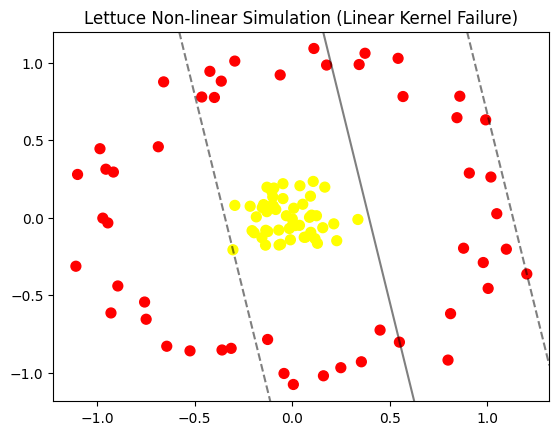

In [15]:
# Menggunakan data non-linear buatan berdasarkan fitur Lettuce (misal mengonversi data melingkar menggunakan TDS dan Humidity)
from sklearn.datasets import make_circles

# Simulasi data non-linear dengan struktur lettuce
X_circle, y_circle = make_circles(100, factor=.1, noise=.1)
clf_circle = SVC(kernel='linear').fit(X_circle, y_circle)

plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='autumn')
plot_svc_decision_function(clf_circle, plot_support=False)
plt.title('Lettuce Non-linear Simulation (Linear Kernel Failure)')
plt.show()

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[582. ,  33.4],
       [451. ,  33.5],
       [678. ,  33.4],
       ...,
       [476. ,  22.5],
       [621. ,  24.6],
       [521. ,  22.6]], shape=(3169, 2)), y=array([0, 0, 0, ..., 1, 1, 1], shape=(3169,)))>

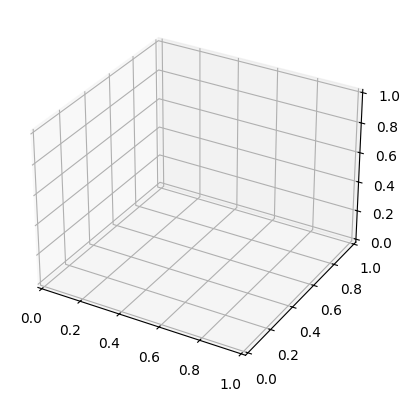

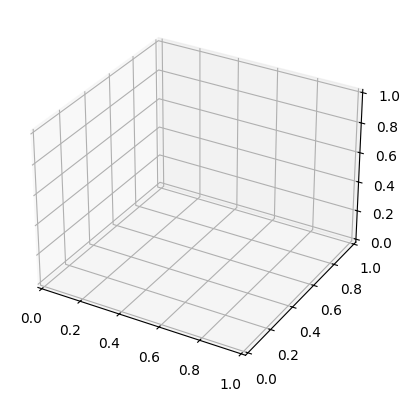

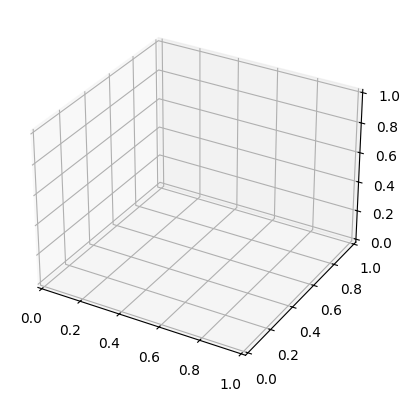

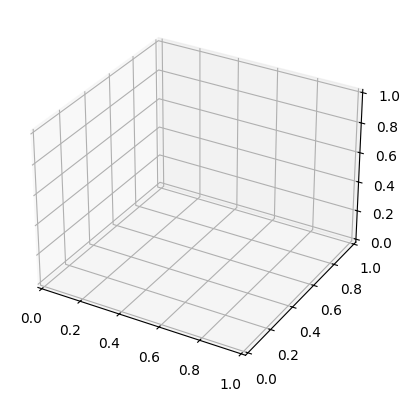

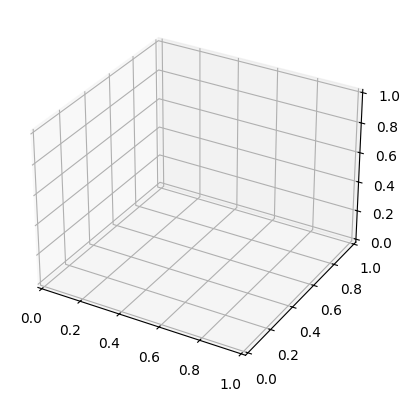

In [16]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
          X=fixed(X), y=fixed(y))

In [17]:
clf = SVC(kernel='rbf', C=1.0)
clf.fit(X, y)

SVC()

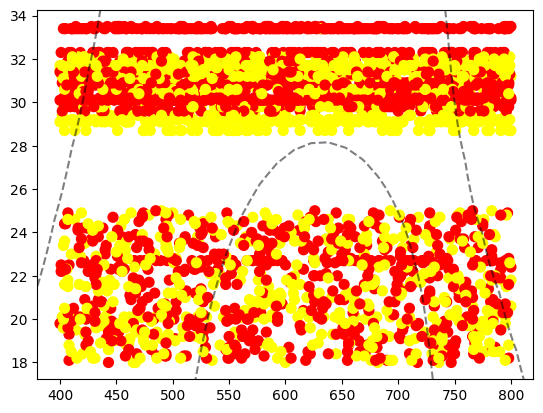

In [18]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

# PRAKTIKUM 3

In [19]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [20]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

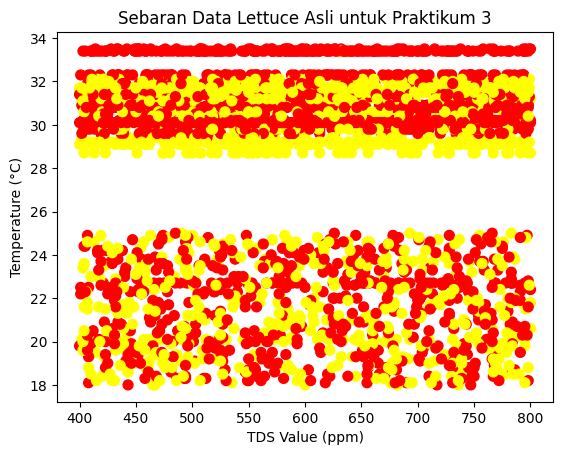

In [21]:
# Menggunakan sebaran data asli Lettuce (TDS vs Temperature) dengan noise alami dibanding make_blobs
X_lettuce = df[['TDS Value (ppm)', 'Temperature (°C)']].values
y_lettuce = df['Growth_Class'].values

plt.scatter(X_lettuce[:, 0], X_lettuce[:, 1], c=y_lettuce, s=50, cmap='autumn')
plt.xlabel('TDS Value (ppm)')
plt.ylabel('Temperature (°C)')
plt.title('Sebaran Data Lettuce Asli untuk Praktikum 3')
plt.show()

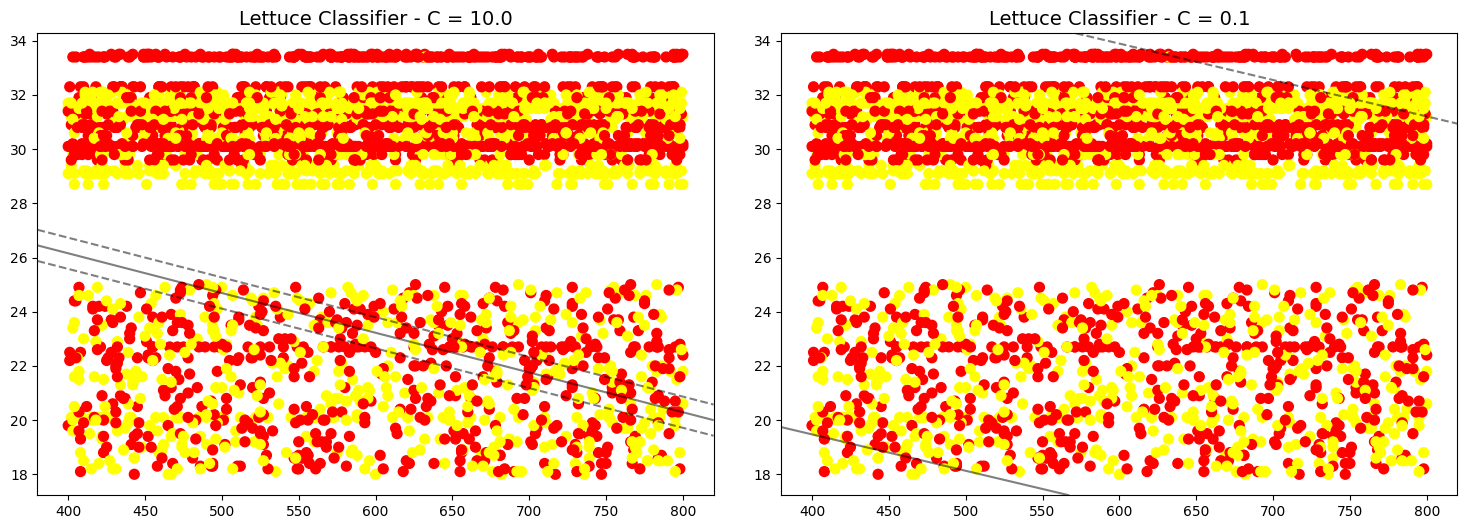

In [22]:
# Eksperimen nilai C pada klasifikasi dataset lettuce
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model_c = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model_c, axi)
    axi.scatter(model_c.support_vectors_[:, 0],
                model_c.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none')
    axi.set_title('Lettuce Classifier - C = {0:.1f}'.format(C), size=14)

# PRAKTIKUM 4

In [23]:
# Di Praktikum 4, kita sesuaikan klasifikasi multi-kelas untuk memprediksi kategori pH Level Lettuce
def pH_category(val):
    if val < 6.2:
        return 0 # Rendah
    elif val <= 6.5:
        return 1 # Optimal
    else:
        return 2 # Tinggi

df['pH_Category'] = df['pH Level'].apply(pH_category)
target_names = ['Rendah (<6.2)', 'Optimal (6.2-6.5)', 'Tinggi (>6.5)']
print("Target Kelas Lettuce:", target_names)
print("Jumlah data per kelas:")
print(df['pH_Category'].value_counts())

Target Kelas Lettuce: ['Rendah (<6.2)', 'Optimal (6.2-6.5)', 'Tinggi (>6.5)']
Jumlah data per kelas:
pH_Category
1    1585
2     991
0     593
Name: count, dtype: int64


In [25]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Pipeline dengan Standard Scaler untuk preprocessing data numerik lettuce
scaler = StandardScaler()
svc = SVC(kernel='rbf', class_weight='balanced')

model_lettuce = make_pipeline(scaler, svc)

In [26]:
# Pembagian data training dan testing untuk klasifikasi multi-kelas pH Lettuce
from sklearn.model_selection import train_test_split

X_multi = df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'Growth Days']].values
y_multi = df['pH_Category'].values

Xtrain, Xtest, ytrain, ytest = train_test_split(X_multi, y_multi, random_state=42)

In [27]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.001, 0.01, 0.1]}
grid = GridSearchCV(model_lettuce, param_grid)

%time grid.fit(Xtrain, ytrain)
print("Parameter Terbaik:", grid.best_params_)
print("Akurasi Terbaik:", grid.best_score_)

CPU times: user 25.1 s, sys: 50.3 ms, total: 25.1 s
Wall time: 25.8 s
Parameter Terbaik: {'svc__C': 50, 'svc__gamma': 0.1}
Akurasi Terbaik: 0.33711189739053515


In [28]:
model_best = grid.best_estimator_
yfit = model_best.predict(Xtest)

In [30]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=target_names))

                   precision    recall  f1-score   support

    Rendah (<6.2)       0.19      0.37      0.25       152
Optimal (6.2-6.5)       0.44      0.25      0.32       396
    Tinggi (>6.5)       0.28      0.31      0.30       245

         accuracy                           0.29       793
        macro avg       0.30      0.31      0.29       793
     weighted avg       0.34      0.29      0.30       793



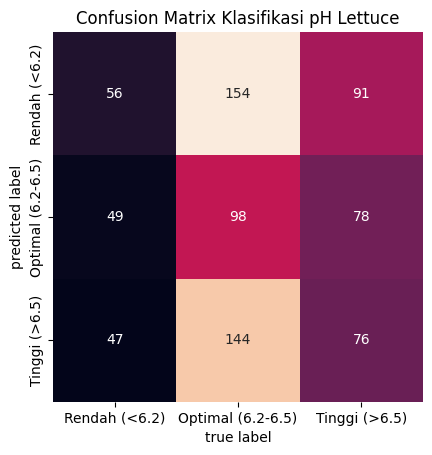

In [31]:
# Kebingungan matriks untuk kelas pH Lettuce
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.title('Confusion Matrix Klasifikasi pH Lettuce')
plt.show()

# PRAKTIKUM 5

In [ ]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [ ]:
# Image directories
train_dir = "/content/drive/MyDrive/images/images/training"
test_dir = "/content/drive/MyDrive/images/images/test"

In [ ]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

In [ ]:
# Load training data
train_img = load_dataset(train_dir)

In [ ]:
# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0]

(array([[[142, 189, 233],
         [144, 191, 235],
         [144, 191, 235],
         ...,
         [150, 193, 236],
         [151, 194, 237],
         [151, 194, 237]],
 
        [[141, 188, 232],
         [144, 191, 235],
         [144, 191, 235],
         ...,
         [156, 199, 242],
         [156, 199, 242],
         [156, 199, 242]],
 
        [[141, 188, 232],
         [144, 191, 235],
         [144, 191, 235],
         ...,
         [153, 196, 239],
         [154, 197, 240],
         [154, 197, 240]],
 
        ...,
 
        [[100,  97,  90],
         [122, 119, 112],
         [126, 123, 114],
         ...,
         [ 83,  87,  98],
         [ 83,  87,  98],
         [ 83,  87,  98]],
 
        [[ 98,  93,  87],
         [124, 119, 113],
         [116, 112, 103],
         ...,
         [ 86,  90, 102],
         [ 85,  89, 101],
         [ 80,  84,  96]],
 
        [[ 99,  94,  88],
         [112, 107, 101],
         [107, 103,  94],
         ...,
         [ 86,  90, 102],
  

In [ ]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 25
(458, 800, 3)


In [ ]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (737, 1024, 3)
Label	: day


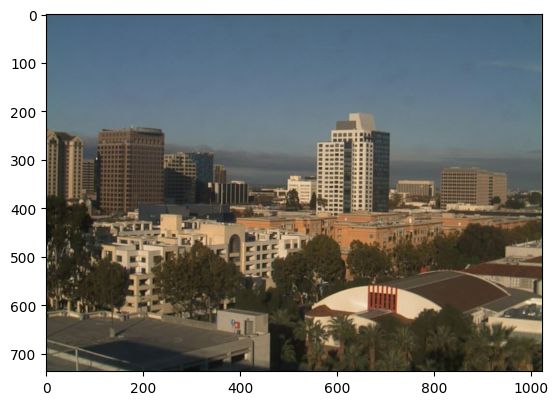

In [ ]:
random_img_viz(train_img)

In [ ]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [ ]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [ ]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [ ]:
train_std_img_list = preprocess(train_img)

In [ ]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 72
(600, 1100, 3)


In [ ]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 148
Avg Brighness: 14.3998


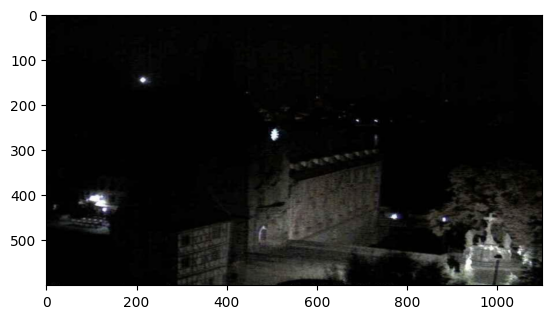

In [ ]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

In [ ]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 40
Actual label: 1
Predicted label: 0


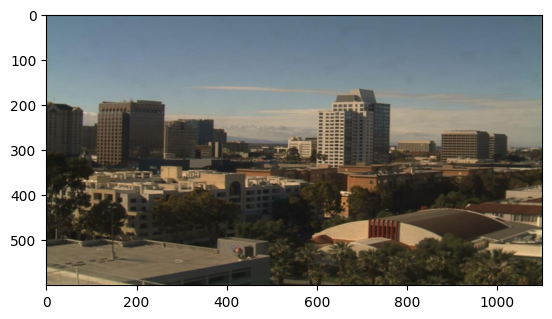

In [ ]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

In [ ]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [ ]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [ ]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [ ]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [ ]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,200.020276,1.0
1,175.092992,1.0
2,103.307636,1.0
3,112.142015,1.0
4,109.947203,1.0


In [ ]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,13.765597,0.0
1,8.217803,0.0
2,13.655582,0.0
3,98.888133,0.0
4,98.235594,0.0


In [ ]:
# import requied library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [ ]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# tugas praktikum
Buatlah model SVM dengan menggunakan data voice.csv dengan ketentuan,

Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.

Gunakan model dengan kernel linier.

Gunakan model dengan kernel polynomial.

Gunakan model dengan kernel RBF.

Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.

Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histrogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tunning dari kernel RBF. Catat performansi akurasinya!

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Menggunakan df lettuce untuk tugas praktikum
# Menentukan target klasifikasi berdasarkan pH Level yang ideal (misal antara 6.0 dan 6.5)
df['pH_Ideal'] = ((df['pH Level'] >= 6.0) & (df['pH Level'] <= 6.5)).astype(int)

# Mengambil fitur-fitur numerik yang relevan
X_lettuce = df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'Growth Days']].values
y_lettuce = df['pH_Ideal'].values

results = []
splits = {'70:30': 0.3, '80:20': 0.2}
kernels = ['linear', 'poly', 'rbf']

for split_name, test_sz in splits.items():
    X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
        X_lettuce, y_lettuce, test_size=test_sz, random_state=42
    )
    for krnl in kernels:
        # Menggunakan cache_size untuk mengoptimalkan performa latih
        clf_lettuce = SVC(kernel=krnl, cache_size=1000)
        clf_lettuce.fit(X_train_l, y_train_l)
        y_pred_l = clf_lettuce.predict(X_test_l)
        acc = accuracy_score(y_test_l, y_pred_l)
        results.append({
            'Split Ratio': split_name,
            'Kernel': krnl,
            'Accuracy': f'{acc:.4f}'
        })

df_results = pd.DataFrame(results)
print("=== Performance Table for Lettuce Dataset ===")
print(df_results.to_markdown(index=False))

=== Performance Table for voice.csv ===
| Split Ratio   | Kernel   |   Accuracy |
|:--------------|:---------|-----------:|
| 70:30         | linear   |     0.9264 |
| 70:30         | poly     |     0.49   |
| 70:30         | rbf      |     0.6625 |
| 80:20         | linear   |     0.9416 |
| 80:20         | poly     |     0.4826 |
| 80:20         | rbf      |     0.6562 |


=== Day/Night Image Classification with HSV Histogram (RBF Kernel) ===
Best Parameters : {'C': 0.1, 'gamma': 'scale'}
Accuracy (80:20) : 0.9875
